# Estimation de l'âge par la voix — Réseau de neurones Dense

**Étapes :**
1. Librosa : un spectrogramme de Mel par locuteur (phrase SA1) = une matrice de nombres (pas une image en couleur)
2. Chercher le spectrogramme **le plus court** et tronquer tous les autres à cette longueur
3. Mettre chaque matrice sous forme de **vecteur** (flatten) → `X_train` de taille (nb_images, taille_vecteur)
4. **4 classes d'âge équilibrées**, numérotées de 0 à 3 → `y_train` en one-hot (nb_images, 4)
5. Réseau `Dense`, sortie `softmax`, perte `categorical_crossentropy`
6. Vérifier si l'accuracy dépasse **25 %** (hasard avec 4 classes équilibrées)

In [12]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from keras.models import Model
from keras.layers import Dense
from keras import Input
from keras.callbacks import EarlyStopping

seed = 7
np.random.seed(seed)

CSV_AGES = "Age_Locuteurs_TIMIT.csv"
PATH = "TIMIT_SA1"

SR = 22050
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 80
N_CLASSES = 4

## 1. Âges et classes équilibrées

On calcule l'âge exact (en années, avec décimales) à partir des dates du CSV. On découpe ensuite les âges du **Train** en 4 quartiles : chaque classe contient environ 25 % des locuteurs.
Les mêmes bornes sont réutilisées pour le Test.

In [14]:
ages = pd.read_csv(CSV_AGES, sep=";")
#ages["Age_exact"] = pd.to_numeric(ages[ages.columns[-1]], errors="coerce") moins bien car si 55 personnes ont 25 ans, ils sont tous dans la même classe
naissance = pd.to_datetime(ages["Date de naissance"], dayfirst=True)
enregistrement = pd.to_datetime(ages["Date enregistrement"], dayfirst=True)
ages["Age_exact"] = (enregistrement - naissance).dt.days / 365.25


is_train_spk = ages["Dataset"] == "Train"
seuils = np.quantile(ages.loc[is_train_spk, "Age_exact"], [0.25, 0.50, 0.75])
bornes = [-np.inf, *seuils, np.inf]

classes = []
"""Pour chaque âge, on part de classe = 0.
On compare l’âge à chaque seuil, et on ajoute 1 à chaque seuil dépassé."""

for age in ages["Age_exact"]:
    classe = 0
    for seuil in seuils:
        if age > seuil:
            classe += 1
    classes.append(classe)



ages["classe"] = classes

print("Bornes des classes (ans) :", np.round(bornes[1:-1], 1))
for c in range(N_CLASSES):
    sel = ages[ages["classe"] == c]
    print(f"Classe {c} : {sel['Age_exact'].min():.1f} à {sel['Age_exact'].max():.1f} ans | "
          f"Train : {(sel['Dataset'] == 'Train').sum()} | Test : {(sel['Dataset'] == 'Test').sum()}")

Bornes des classes (ans) : [25.  27.4 32.8]
Classe 0 : 20.6 à 25.0 ans | Train : 116 | Test : 41
Classe 1 : 25.0 à 27.4 ans | Train : 115 | Test : 37
Classe 2 : 27.4 à 32.8 ans | Train : 115 | Test : 47
Classe 3 : 32.8 à 75.8 ans | Train : 115 | Test : 43


## 2. Liste des fichiers SA1 (un par locuteur)

In [15]:
dossier = "TIMIT_SA1"

chemins = []
#Boucle pour créer les chemins d'accès aux fichiers audio
for i in range(len(ages)):
    jeu = ages["Dataset"][i].upper()          # "Train" -> "TRAIN"
    region = ages["Region"][i]                # "DR1"
    locuteur = ages["Locuteur"][i]            # "FAKS0"
    chemins.append(dossier + "/" + jeu + "/" + jeu + "_" + region + "_" + locuteur + "_SA1.WAV")

ages["path"] = chemins
files = ages

print(len(files), "fichiers")

629 fichiers


## 3. Sortie de librosa

Pour chaque fichier, on calcule le spectrogramme de Mel en dB puis on le normalise entre 0 et 1.
Le résultat est une **matrice de nombres** de taille $(80, t)$ : 80 bandes de Mel et $t$ trames temporelles. Les couleurs de `specshow` ne servent qu'à l'affichage, le réseau ne travaille que sur ces nombres.

On retire aussi le silence au début et à la fin (`librosa.effects.trim`), sinon le spectrogramme le plus court contiendrait surtout du silence.

In [16]:
def mel_spectrogram_norm(path):
    """Fonction qui calcule le spectrogramme de Mel normalisé d'un fichier audio donné."""
    y, sr = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT,
                                                     hop_length=HOP_LENGTH, n_mels=N_MELS)
    mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)
    return ((mel_spectrogram_db - mel_spectrogram_db.min())
            / (mel_spectrogram_db.max() - mel_spectrogram_db.min()))

spectros = [mel_spectrogram_norm(p) for p in files["path"]]

print(spectros[0].shape, "->", spectros[0].min(), spectros[0].max())
print(spectros[49].shape, "->", spectros[49].min(), spectros[49].max())

(80, 101) -> 0.0 1.0
(80, 156) -> 0.0 1.0


## 4. Même longueur : on tronque au plus court

On cherche le nombre de trames $t_{min}$ du spectrogramme le plus court, puis on garde les $t_{min}$ premières trames de chaque spectrogramme.
Tous les locuteurs lisent la même phrase SA1, donc les premières trames correspondent au même début de phrase pour tout le monde.

In [17]:
longueurs = []
#Boucle qui parcourt les spectrogrammes et stocke la longueur de chaque spectrogramme dans la liste longueurs
for S in spectros:
    longueurs.append(S.shape[1])

t_min = min(longueurs)
print("Longueur min :", t_min, "trames | max :", max(longueurs), "trames")
print(f"t_min = {t_min} trames ≈ {t_min * HOP_LENGTH / SR:.2f} s\n")

spectros_coupes = [S[:, :t_min] for S in spectros]
print("Forme après troncature :", spectros_coupes[0].shape,"\n")

print(f"1er spectrogramme: {spectros_coupes[0].shape}")
print(f"50ème spectrogramme: {spectros_coupes[49].shape}")

Longueur min : 90 trames | max : 217 trames
t_min = 90 trames ≈ 2.09 s

Forme après troncature : (80, 90) 

1er spectrogramme: (80, 90)
50ème spectrogramme: (80, 90)


## 5. Matrice → vecteur (flatten)

Une couche `Dense` prend un vecteur en entrée. On met les lignes de la matrice bout à bout :

In [18]:
X = np.array([S.flatten() for S in spectros_coupes])
print("X0 :", X[0],"\n")
y = files["classe"].to_numpy()

is_train = (files["Dataset"] == "Train").to_numpy()
is_test  = (files["Dataset"] == "Test").to_numpy()

X_train, y_train = X[is_train], y[is_train]
X_test,  y_test  = X[is_test], y[is_test]

#Standardisation : on soustrait la moyenne et on divise par l'écart-type
#Il reste les écarts à la moyenne, ce qui distingue un locuteur d'un autre, mais on ne tient pas compte de l'amplitude du signal
moyenne = X_train.mean(axis=0)
ecart_type = X_train.std(axis=0) + 1e-8
X_train = (X_train - moyenne) / ecart_type
X_test  = (X_test  - moyenne) / ecart_type

# One-hot : classe 2 -> [0, 0, 1, 0]
#M atrice identité de taile 4x4
Y_train = np.eye(N_CLASSES)[y_train]
Y_test  = np.eye(N_CLASSES)[y_test]

print("X_train :", X_train.shape, "| Y_train :", Y_train.shape)
print("X_test  :", X_test.shape,  "| Y_test  :", Y_test.shape, "\n")
print("Exemple : classe", y_train[0], "->", Y_train[0])

X0 : [0.15394334 0.21095619 0.22780237 ... 0.         0.         0.        ] 

X_train : (461, 7200) | Y_train : (461, 4)
X_test  : (168, 7200) | Y_test  : (168, 4) 

Exemple : classe 1 -> [0. 1. 0. 0.]


## 6. Réseau de neurones

Sortie : un vecteur de 4 valeurs avec `softmax` (fonction d'activation qui donne une probabilité par classe, dont la somme vaut 1).

In [19]:
InputLayer = Input(shape=(X_train.shape[1],))
x = Dense(32, activation='relu')(InputLayer)
x = Dense(16, activation='relu')(x)
output = Dense(N_CLASSES, activation='softmax')(x)

model = Model(inputs=InputLayer, outputs=output)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │       230,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 231,028 (902.45 KB)

 Trainable params: 231,028 (902.45 KB)

 Non-trainable params: 0 (0.00 B)

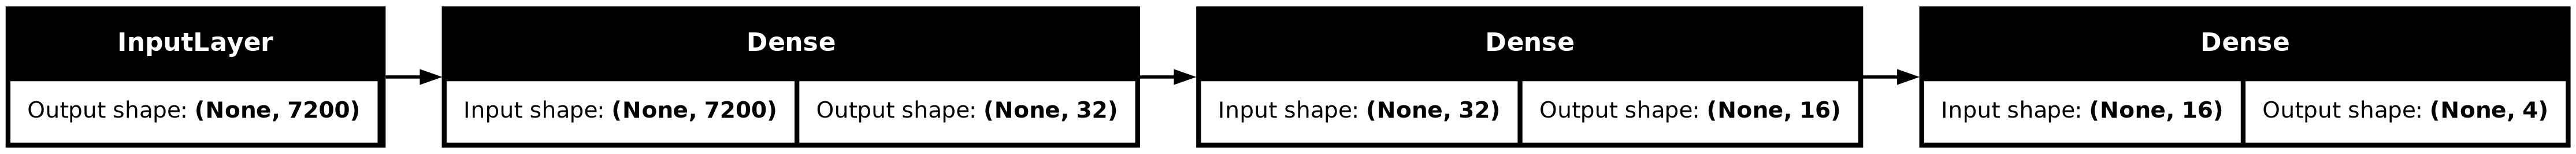

In [20]:

from keras.utils import plot_model

plot_model(model, show_shapes=True, to_file='model_structure.png', rankdir='LR')

In [21]:
# Callback : arrête l'entraînement quand l'erreur de validation ne baisse plus
arret = EarlyStopping(monitor='val_loss',          
                      patience=10,                 
                      restore_best_weights=True,  
                      verbose=1)                   

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, Y_train, epochs=300, batch_size=32,
                    validation_data=(X_test, Y_test),
                    callbacks=[arret])

print("Meilleure époque :", np.argmin(history.history['val_loss']) + 1)

Epoch 1/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.2408 - loss: 1.9868 - val_accuracy: 0.2976 - val_loss: 1.7311
Epoch 2/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4664 - loss: 1.2299 - val_accuracy: 0.3690 - val_loss: 1.7450
Epoch 3/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6334 - loss: 0.8475 - val_accuracy: 0.3214 - val_loss: 1.9535
Epoch 4/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8048 - loss: 0.5361 - val_accuracy: 0.3155 - val_loss: 1.9882
Epoch 5/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8807 - loss: 0.3505 - val_accuracy: 0.3214 - val_loss: 2.1495
Epoch 6/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9436 - loss: 0.2391 - val_accuracy: 0.3512 - val_loss: 2.1930
Epoch 7/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9696 - loss: 0.1800 - val_accuracy: 0.3452 - val_loss: 2.3355
Epoch 8/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9783 - loss: 0.1266 - val_accuracy: 0.3393 

## 7. Résultats : est-ce qu'on dépasse 25 % ?

In [22]:
y_p = model.predict(X_test).argmax(axis=1)
print(f"\nAccuracy sur le test : {np.mean(y_p == y_test):.1%}  (hasard : 25 %)\n")

# Matrice de confusion (lignes = vraie classe, colonnes = prédiction)
conf = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
for t, p in zip(y_test, y_p):
    conf[t, p] += 1
print(pd.DataFrame(conf, index=[f"vraie {c}" for c in range(N_CLASSES)],
                   columns=[f"prédite {c}" for c in range(N_CLASSES)]))

print("\n")
classe_majoritaire = np.bincount(y_train).argmax()
print(f"Référence (toujours prédire {classe_majoritaire}) : {np.mean(y_test == classe_majoritaire):.1%}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

Accuracy sur le test : 29.8%  (hasard : 25 %)

         prédite 0  prédite 1  prédite 2  prédite 3
vraie 0         11         15          7          8
vraie 1         10         15          6          6
vraie 2          9         14         16          8
vraie 3          6         19         10          8


Référence (toujours prédire 0) : 24.4%
